# W12A 실습 A · 캠퍼스 영화제 편성회의

**딥러닝응용I(추천시스템) 01 · 2026-11-17 · 9.2–9.3 실습**

오늘은 영화제 편성자와 검수자가 한 팀입니다. 편성자는 관객 취향 카드로 모델을 호출하고 검수자는 원응답에서 조건과 근거를 확인합니다. 1라운드 뒤 역할을 바꾸세요.

**미션** · 상영 후보 최대 3편. 95분 이하. 공포 제외. 이미 본 영화 제외. 선호는 조용한 SF와 따뜻한 우정입니다. 가상 영화와 관객 사례만 사용합니다.

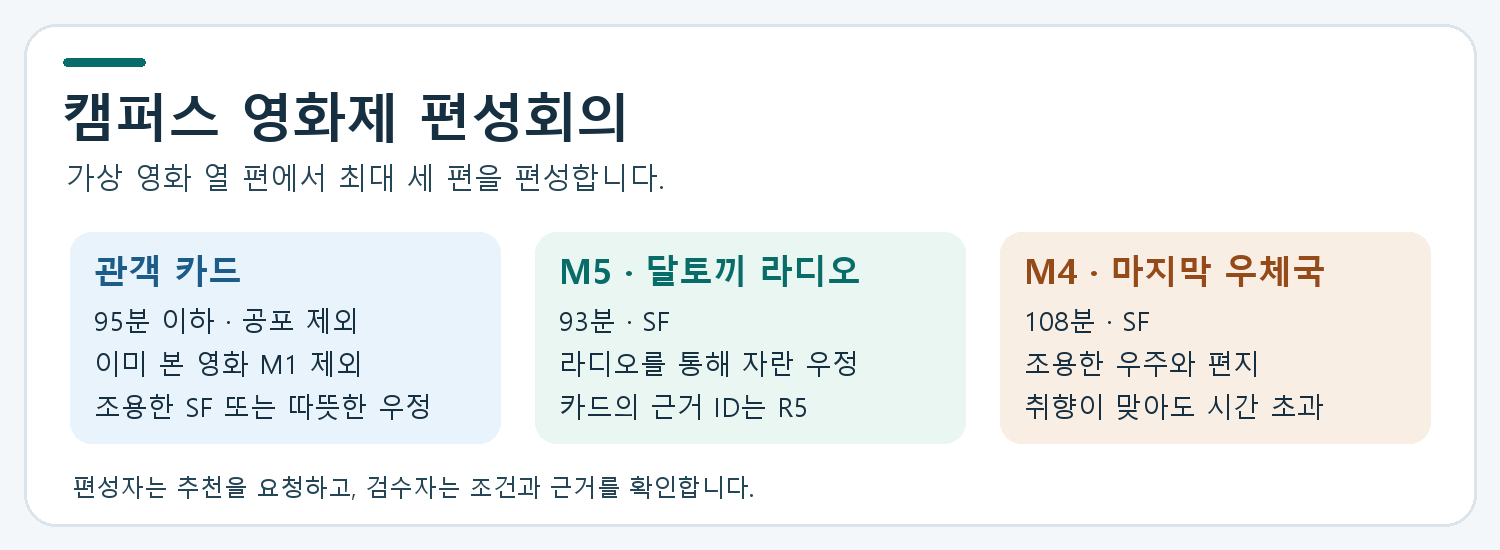


[Figure source](https://raw.githubusercontent.com/lunalab-ai/recommender/2026-fall-w12a/course/notion/assets/w12a/01-festival.png)


In [ ]:
import os
import sys
import json
import subprocess
from pathlib import Path
from urllib.request import urlopen
from time import perf_counter
from IPython.display import display

TAG = "2026-fall-w12a"
ROOT_URL = f"https://raw.githubusercontent.com/lunalab-ai/recommender/{TAG}/"
IN_COLAB = "google.colab" in sys.modules
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    f"luna-recommender-course[llm] @ git+https://github.com/lunalab-ai/recommender.git@{TAG}"],
                   check=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from luna_recsys.festival_lab import BALLOT, KEYS, NEIGHBORS, catalog, run_ballot, review_experiment, synthetic_fm_rows
from luna_recsys.festival_runtime import prepare_festival, ensure_model, EMBED_MODEL
from luna_recsys.embedding_fm import make_feature_recipe, fit_embedding_fm, evaluate_embedding_fm

CACHE = Path(os.environ.get("LUNA_W12A_CACHE", Path.home() / ".cache/luna-recsys/w12a"))
cards = catalog()
ballot = BALLOT.copy()
display(cards)


### 준비하는 동안 · 조건을 보고 손으로 한 편 고르기

M1의 내용이 취향에 맞더라도 M1을 편성할 수 있을까요? 영화 ID와 근거 ID는 어떻게 다른가요?

무료 CPU가 생성 모델을 먼저 준비합니다. 압축 실행 파일과 모형의 최초 다운로드는 수 분 걸릴 수 있습니다. Colab 기본 CPU로 시작하세요. API 키가 필요하지 않습니다. 준비가 막히거나 팀별 출발 시간이 다르면 아래 값을 직접 "replay"로 바꾸고 이 셀부터 다시 실행하세요. 재생에서는 실제 기록의 검수만 수행하며 새로운 문장을 생성하지 않습니다.


In [ ]:
MODE = "live"  # "replay"로 직접 바꾸면 미리 기록한 실제 요청·응답을 사용합니다.
trace = None
client = None
if MODE == "live":
    start = perf_counter()
    client = prepare_festival(CACHE / "runtime")
    print("실시간 CPU 준비 초:", round(perf_counter() - start, 2))
elif MODE == "replay":
    local = Path(__import__("luna_recsys").__file__).resolve().parents[2] / "course/assets/w12a/replay.json"
    if local.is_file():
        trace = json.loads(local.read_text(encoding="utf-8"))
    else:
        with urlopen(ROOT_URL + "course/assets/w12a/replay.json", timeout=45) as response:
            trace = json.load(response)
    print("기록 재생 · Ollama", trace["server_version"], "· 새로운 생성 호출 없음")
else:
    raise ValueError("MODE는 live 또는 replay입니다.")


### 미션 1 · 이웃 사례와 영화 리뷰를 바꿔 보기

같은 후보와 관객 요청으로 CF와 CB를 비교합니다. CF는 비슷한 관객이 본 영화 목록을 읽습니다. CB는 영화 카드의 리뷰를 읽습니다. 두 요청 모두 LLM의 가중치는 고정입니다.

아래 본문 함수의 후보와 근거 구성을 읽으세요. 교대 후 CF에서 N3를 제외하도록 실제 함수 본문을 한 군데만 고치세요. 다시 실행하면 전송 로그가 바뀝니다. 모델 답이 같더라도 입력 해시를 비교할 수 있습니다.

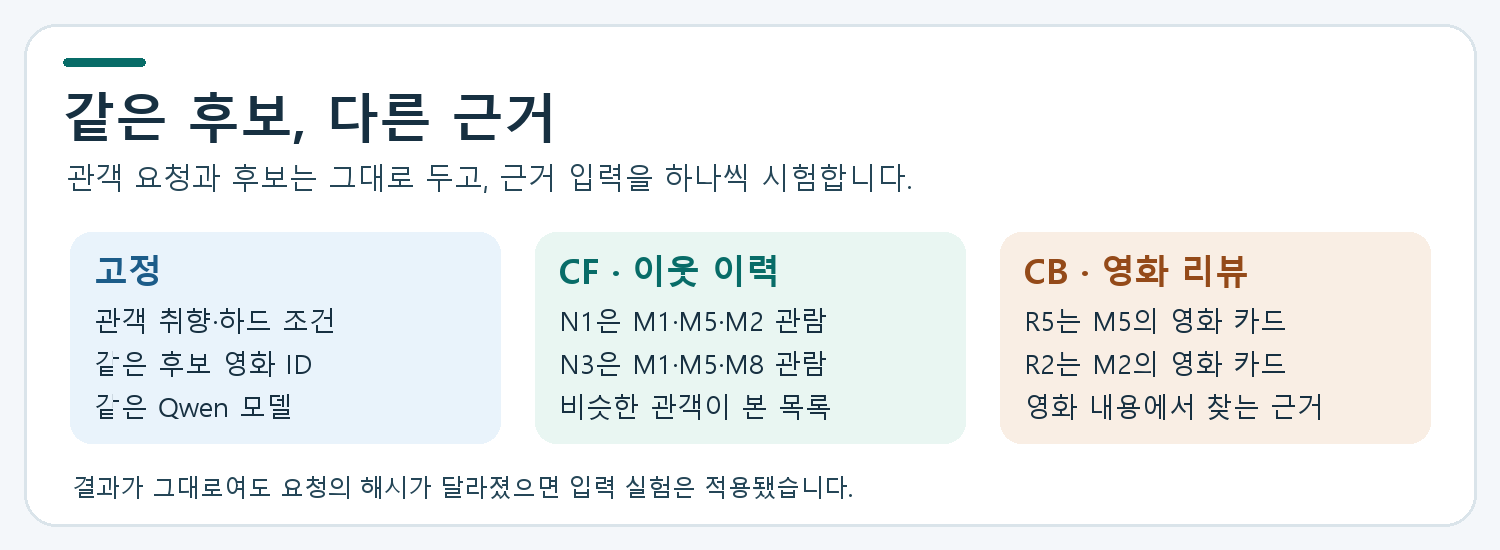


[Figure source](https://raw.githubusercontent.com/lunalab-ai/recommender/2026-fall-w12a/course/notion/assets/w12a/02-evidence.png)


In [ ]:
def eligibility(card: dict, ballot: dict) -> list[str]:
    """One candidate's hard policy. An empty list means it is eligible."""
    issues = []
    if card["minutes"] > ballot["max_minutes"]:
        issues.append("too_long")
    if card["genre"] in ballot["exclude"]:
        issues.append("excluded_genre")
    if card["movie_id"] in ballot["seen"]:
        issues.append("already_seen")
    return issues


In [ ]:
def build_ballot_prompt(cards, ballot, method="CB", *, prefilter=False):
    """Expose the candidate and evidence paths before sending the actual prompt."""
    rows = cards.to_dict("records")
    candidate_pool = [card for card in rows if not prefilter or not eligibility(card, ballot)]
    known = {card["movie_id"] for card in candidate_pool}
    if method == "CF":
        examples = {name: [movie for movie in items if movie in known]
                    for name, items in NEIGHBORS.items()}
        evidence = {name: set(items) for name, items in examples.items()}
        evidence_text = examples
    elif method == "CB":
        evidence = {f"R{card['movie_id'][1:]}": {card["movie_id"]} for card in candidate_pool}
        evidence_text = {f"R{card['movie_id'][1:]}": card["review"] for card in candidate_pool}
    else:
        raise ValueError("Choose CF or CB.")
    payload = {
        "request": ballot,
        "candidates": [[c["movie_id"], c["minutes"], c["genre"]] for c in candidate_pool],
        "evidence": evidence_text,
    }
    messages = [
        {"role": "system", "content": "Select up to 3 eligible movies. Use candidate ID and "
         "a valid evidence ID for each. Enforce minutes, exclusions and seen IDs. "
         "Never invent an ID. Use a very short reason. Return JSON."},
        {"role": "user", "content": json.dumps(payload, ensure_ascii=False)},
    ]
    return messages, known, evidence


### 원응답을 검수하기

모델이 만든 JSON을 그대로 보고 각 행을 아래 함수로 검사합니다. 근거 ID가 영화에 연결되는지와 자연어 설명이 그 사실을 충실히 옮겼는지를 따로 보세요. 자연어 설명은 옆 팀에서 원래 카드와 대조합니다.


In [ ]:
def validate_ballot(raw, cards, ballot, candidate_ids, evidence):
    """Check semantics independently of the LLM and retain every rejection reason."""
    by_id = {card["movie_id"]: card for card in cards.to_dict("records")}
    try:
        decoded = json.loads(raw)
        picks = decoded["picks"]
        if not isinstance(picks, list):
            raise ValueError("picks must be a list")
    except (ValueError, KeyError, TypeError):
        return pd.DataFrame([{"movie_id": "", "evidence": "", "reason": "",
                              "accepted": False, "issues": "malformed_json"}])
    seen = set()
    rows = []
    for position, pick in enumerate(picks):
        if not isinstance(pick, dict) or any(not isinstance(pick.get(k), str) for k in KEYS):
            rows.append({"movie_id": "", "evidence": "", "reason": "",
                         "accepted": False, "issues": "malformed_row"})
            continue
        movie, reference = pick["movie_id"], pick["evidence"]
        issues = []
        if movie not in candidate_ids:
            issues.append("outside_candidates")
        if movie in by_id:
            issues.extend(eligibility(by_id[movie], ballot))
        if movie in seen:
            issues.append("duplicate")
        if movie not in evidence.get(reference, set()):
            issues.append("evidence_mismatch")
        if position >= 3:
            issues.append("too_many")
        seen.add(movie)
        rows.append({**{key: pick[key] for key in KEYS}, "accepted": not issues, "issues": ", ".join(issues)})
    return pd.DataFrame(rows, columns=[*KEYS, "accepted", "issues"])


In [ ]:
def perform(method, prefilter=False):
    if MODE == "live":
        record, checked = run_ballot(client, cards, ballot, method, prefilter=prefilter,
                                     prompt_fn=build_ballot_prompt, validate_fn=validate_ballot)
    else:
        record = next(row for row in trace["chat"]
                      if (row["method"], row["prefilter"]) == (method, prefilter))
        checked = validate_ballot(record["raw"], cards, record["ballot"], set(record["candidate_ids"]),
                                  {key: set(value) for key, value in record["evidence"].items()})
    print("실시간 생성" if MODE == "live" else "실제 호출 기록 재생", method, "사전 필터", prefilter)
    print("실제 요청:", record["prompt"][-1]["content"], "\n입력 SHA:", record["prompt_sha256"])
    print("원응답:", record["raw"], "\n호출 정보:", record["observed"])
    print("후보 수", len(record["candidate_ids"]), "조건 통과 후보 수", record["eligible_count"],
          "최종 통과", int(checked.accepted.sum()))
    display(checked)
    return record, checked

cf_record, cf_audit = perform("CF")
cb_record, cb_audit = perform("CB")


### 미션 2 · 말로 준 조건을 코드로 옮기기

사전 필터를 켜고 미션 1의 CB와 비교합니다. 어떤 영화가 후보에서 빠졌으며 무엇이 여전히 검수에 남나요?

두 번째 관객은 최대 88분, 공포 또는 SF 제외, M2를 이미 봤습니다. live에서는 ballot을 이 요청으로 바꿔 한 번 더 실행하세요. replay에서는 원응답에 같은 새 조건을 적용해 편성안 재검수만 수행하세요. 사전 필터 코드 본문 한 줄을 바꿨다면 함수 정의부터 다시 실행합니다.

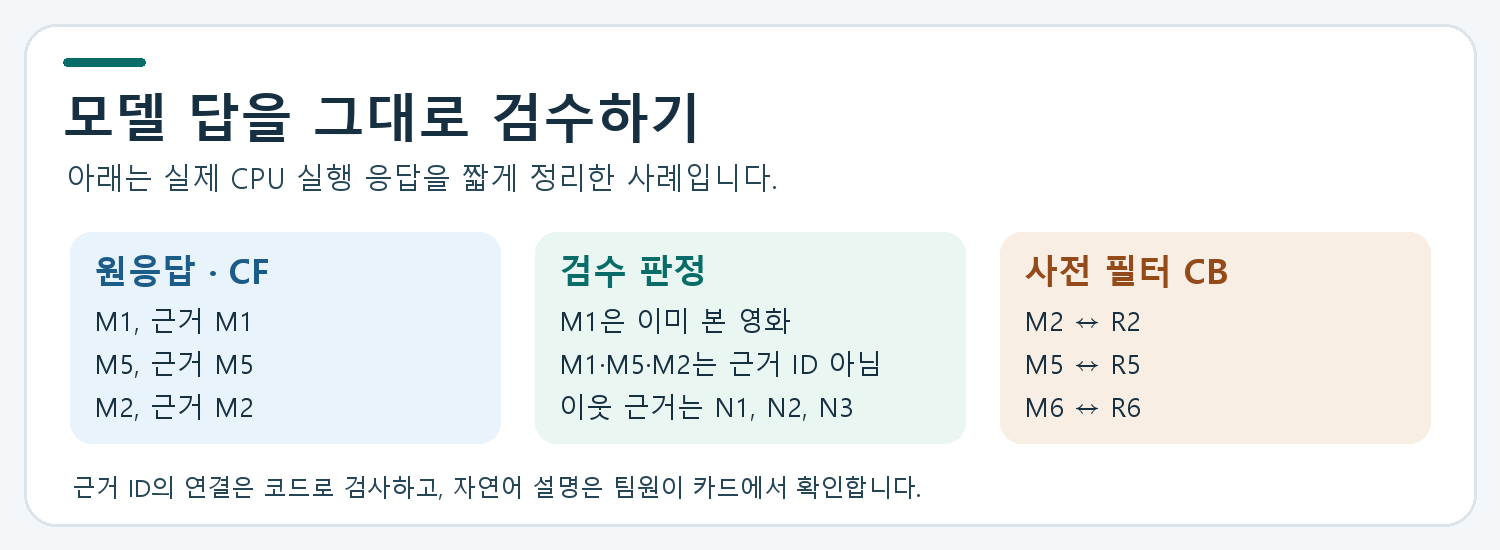


[Figure source](https://raw.githubusercontent.com/lunalab-ai/recommender/2026-fall-w12a/course/notion/assets/w12a/03-audit.png)


In [ ]:
prefilter_record, prefilter_audit = perform("CB", prefilter=True)
MY_OBSERVATION = ""  # 모델이 해 준 판단과 코드가 확인한 판단을 각각 한 문장으로 적으세요.


### 미션 3 · 같은 리뷰를 숫자로 읽기

리뷰 4편과 검색문을 Nomic으로 벡터화합니다. 한 문장만 바꿔 코사인 유사도 순서가 어떻게 달라지는지 기록하세요. 가로축 값은 두 벡터의 방향 유사도입니다.

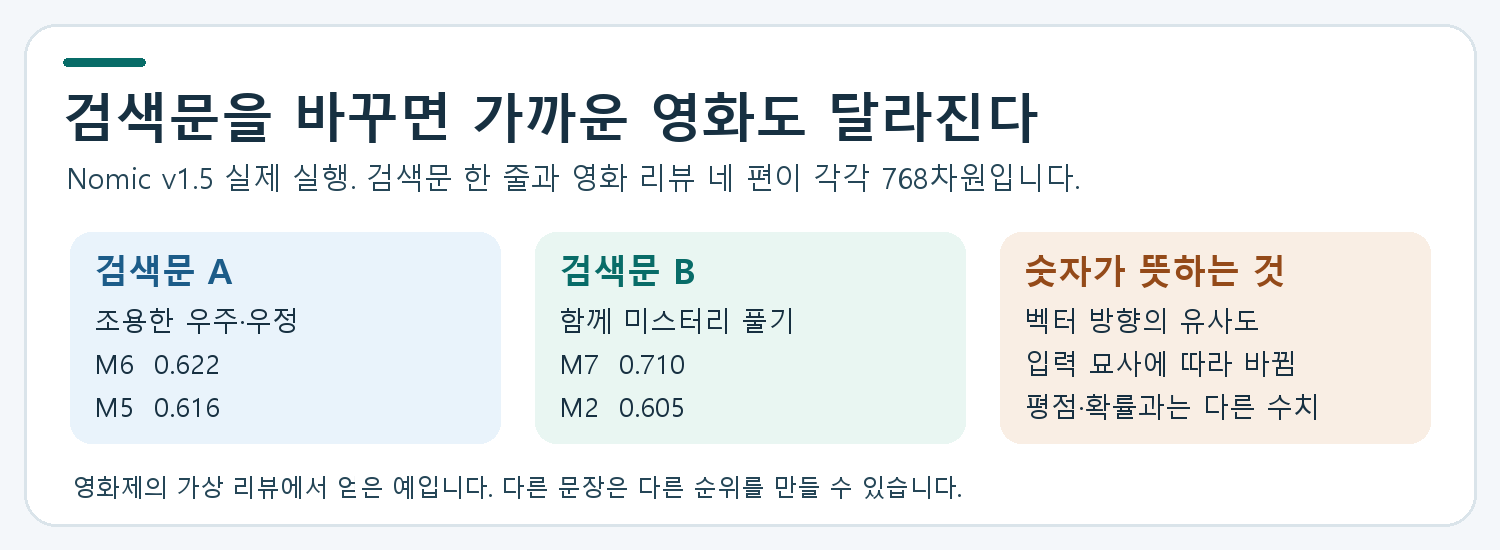


[Figure source](https://raw.githubusercontent.com/lunalab-ai/recommender/2026-fall-w12a/course/notion/assets/w12a/04-embeddings.png)


In [ ]:
reviews = cards.set_index("movie_id").loc[["M2", "M5", "M6", "M7"], "review"].to_dict()
query_a = "quiet space stories about friendship"
query_b = "people solve a mystery together"
if MODE == "live":
    ensure_model(client, EMBED_MODEL)
    first, first_vectors, first_meta = review_experiment(client, query_a, reviews)
    second, second_vectors, second_meta = review_experiment(client, query_b, reviews)
else:
    first, second = [pd.DataFrame(row["table"]) for row in trace["embeddings"]]
    first_vectors, second_vectors = [np.asarray(row["vectors"]) for row in trace["embeddings"]]
    first_meta, second_meta = [row["observed"] for row in trace["embeddings"]]
print("검색문+리뷰 배열", first_vectors.shape, first_meta, second_meta)
print("앞 5개 성분:", np.round(first_vectors[0, :5], 4))
comparison = first.set_index("movie_id").join(second.set_index("movie_id"), lsuffix="_A", rsuffix="_B")
display(comparison)
ax = comparison.plot.barh(color=["#10648d", "#d56726"], figsize=(7, 2.7))
ax.set_xlabel("Cosine similarity")
plt.show()


### 미션 4 · 벡터가 평점 모형에 들어가는 한 줄

ID만 쓰는 FM과 리뷰 벡터를 추가한 FM을 동일한 가상 훈련/검증 행에서 학습합니다. 원핫 블록 뒤에 사용자·영화 리뷰 벡터가 어디에 붙는지 아래에서 찾아보세요. 추가 실험으로 사용자 벡터 대입 줄을 0으로 바꾸고 재학습하세요. replay에서는 실제 실행 기록의 폭·오차를 읽고 바꿀 줄을 표시하세요.

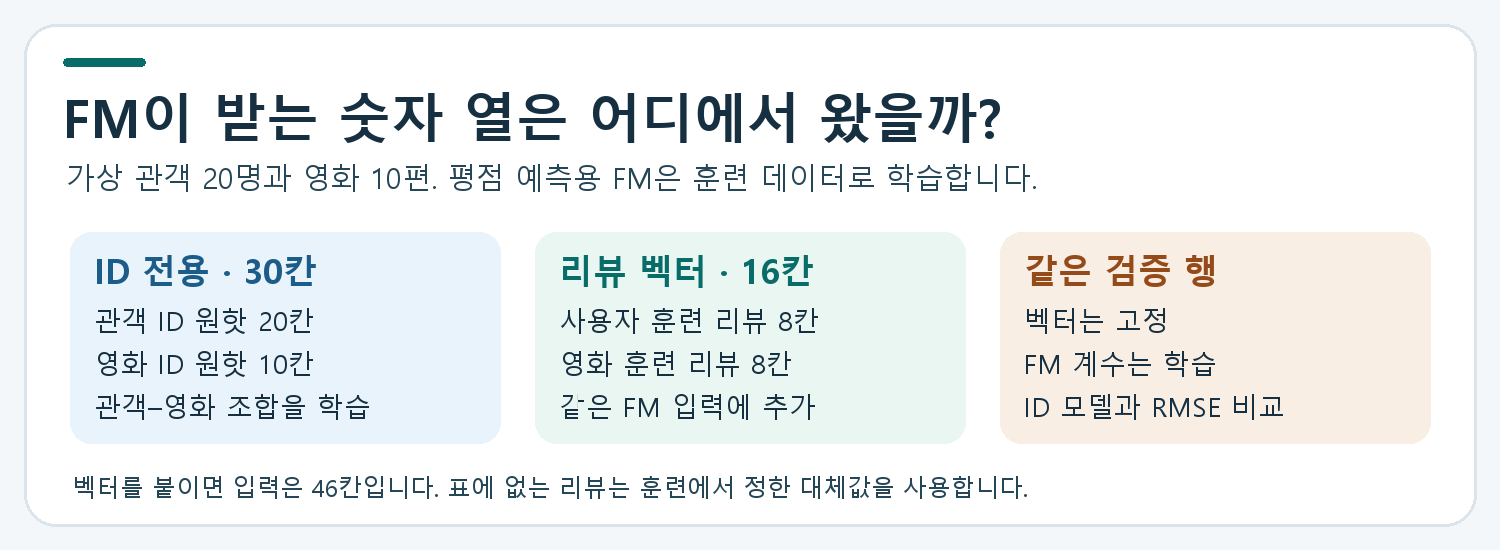


[Figure source](https://raw.githubusercontent.com/lunalab-ai/recommender/2026-fall-w12a/course/notion/assets/w12a/05-fm.png)


In [ ]:
def assemble_features(user: str, item: str, recipe: dict, use_embeddings: bool = True) -> np.ndarray:
    """One observation -> [user one-hot,item one-hot,user vector,item vector].

    n=U+I+2d with embeddings, U+I without. Unknown IDs have zero ID blocks and
    training-mean vectors; their absence is separately reported by prediction.
    """
    n_users, n_items, d = len(recipe['users']), len(recipe['items']), recipe['dimension']
    out = np.zeros(n_users + n_items + (2*d if use_embeddings else 0))
    if user in recipe['user_index']:
        out[recipe['user_index'][user]] = 1.
    if item in recipe['item_index']:
        out[n_users + recipe['item_index'][item]] = 1.
    if use_embeddings:
        offset = n_users + n_items
        out[offset:offset+d] = recipe['user_vectors'].get(user, recipe['default_user'])
        out[offset+d:offset+2*d] = recipe['item_vectors'].get(item, recipe['default_item'])
    return out


In [ ]:
if MODE == "live":
    parts = synthetic_fm_rows()
    recipe = make_feature_recipe(parts["train"], client, CACHE / "features")
    grades = []
    for use_text in (False, True):
        fitted = fit_embedding_fm(parts, recipe, use_embeddings=use_text, epochs=12,
                                  feature_fn=assemble_features)
        validation = evaluate_embedding_fm(fitted, parts["validation"])
        assert fitted["validation_rows"] == tuple(parts["validation"].row_id)
        grades.append(("ID + text" if use_text else "ID only", len(fitted["feature_names"]),
                       fitted["state"]["epoch"], validation["rmse"]))
    print("실제 모형 입력", recipe["metadata"], "분할", {k: len(v) for k, v in parts.items()})
    display(pd.DataFrame(grades, columns=["features", "width", "epoch", "validation_rmse"]))
else:
    print("실제 학습 기록 재생", trace["fm_rows"], trace["fm_encoder"])
    display(pd.DataFrame(trace["fm"]))


In [ ]:
assert list(cf_audit.columns) == [*KEYS, "accepted", "issues"]
assert first_vectors.shape == second_vectors.shape == (5, 768)
assert set(first.movie_id) == set(second.movie_id) == set(reviews)
assert set(prefilter_audit.loc[prefilter_audit.accepted, "movie_id"]).issubset(prefilter_record["candidate_ids"])
if MODE == "live":
    assert len(client.calls) >= 5 and grades[0][1] == 30 and grades[1][1] == 46
print("W12A_A_RUNTIME_CHECKS_PASSED")


In [ ]:
print("W12A_A_RUN_ALL_OK")
